# 01 — Analyse exploratoire (EDA)

**Dataset :** CT Kidney Dataset (Normal / Cyst / Tumor / Stone), Kaggle `nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone`.

Ce notebook décrit les **données brutes** (`archive/`) telles qu'elles sont téléchargées. Il est volontairement
**autonome** (il n'importe rien de `src/`) et **figé** : il documente l'état initial des données et justifie
les choix de prétraitement faits dans `02_preprocessing_cleaning.ipynb`.

**Plan**
1. Inventaire des fichiers
2. Répartition des classes
3. Format des images (mode, canaux)
4. Dimensions et types de coupe (axiale / coronale)
5. Exemples visuels
6. Intensités des pixels
7. Doublons exacts
8. Coupes consécutives quasi identiques → risque de fuite de données
9. Conclusions → décisions de prétraitement

In [1]:
import os, sys
from pathlib import Path

# Le notebook tourne depuis notebooks/ : on se place à la racine du projet
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import hashlib, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

RAW_DIR = Path("archive/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone")
CLASSES = ["Cyst", "Normal", "Stone", "Tumor"]

# Palette catégorielle à ordre fixe (une couleur = une classe dans tout le notebook)
CLASS_COLORS = {"Cyst": "#2a78d6", "Normal": "#eb6834", "Stone": "#1baf7a", "Tumor": "#eda100"}
VIEW_COLORS = {"axial": "#2a78d6", "coronal": "#eb6834"}
INK_MUTED, GRID, AXIS = "#6b6a63", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": AXIS,
    "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "axes.titleweight": "bold",
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "lines.linewidth": 2, "legend.frameon": False,
})

## 1. Inventaire des fichiers

On parcourt `archive/` et on construit un tableau avec une ligne par image : classe, numéro dans le nom de fichier,
dimensions, hash md5, et quelques statistiques calculées sur une miniature 64×64 (décodage JPEG réduit, rapide).

In [2]:
print("Sous-dossiers :", sorted(p.name for p in RAW_DIR.iterdir()))
print("Extensions   :", sorted({p.suffix for p in RAW_DIR.rglob("*") if p.is_file()}))
print("Exemples     :", [p.name for p in sorted((RAW_DIR / "Cyst").glob("*.jpg"))[:3]])

Sous-dossiers : ['Cyst', 'Normal', 'Stone', 'Tumor']


Extensions   : ['.jpg']
Exemples     : ['Cyst- (1).jpg', 'Cyst- (10).jpg', 'Cyst- (100).jpg']


In [3]:
rows = []
for cls in CLASSES:
    for f in (RAW_DIR / cls).glob("*.jpg"):
        with Image.open(f) as im:
            w, h, mode = *im.size, im.mode
            im.draft("RGB", (128, 128))
            small = np.asarray(im.convert("RGB").resize((64, 64)), dtype=np.float32)
        gray = small.mean(2)
        rows.append({
            "file": f.name, "cls": cls, "num": int(re.search(r"\((\d+)\)", f.name).group(1)),
            "width": w, "height": h, "mode": mode,
            "channels_equal": bool(np.abs(small[..., 0] - small[..., 1]).max() < 2
                                   and np.abs(small[..., 1] - small[..., 2]).max() < 2),
            "mean_intensity": gray.mean(), "black_fraction": (gray < 10).mean(),
            "md5": hashlib.md5(f.read_bytes()).hexdigest(), "path": str(f),
        })
df = pd.DataFrame(rows).sort_values(["cls", "num"]).reset_index(drop=True)
df["view"] = np.where(df["width"] == df["height"], "axial", "coronal")
print(f"{len(df)} images")
df.head()

12446 images


,file,cls,num,width,height,mode,channels_equal,mean_intensity,black_fraction,md5,path,view
0,Cyst- (1).jpg,Cyst,1,705,569,RGB,True,40.192871,0.571777,1b69ba00940b8e23df5f1f62349528fb,archive/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-St...,coronal
1,Cyst- (2).jpg,Cyst,2,512,512,RGB,True,22.558594,0.598145,8ba170c5e054f6ada63ecb1b2d8952af,archive/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-St...,axial
2,Cyst- (3).jpg,Cyst,3,512,512,RGB,True,22.517334,0.595215,d81ddff68bc8a0f1357cb5f38d5dbc60,archive/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-St...,axial
3,Cyst- (4).jpg,Cyst,4,512,512,RGB,True,22.442627,0.598877,9cae678b68cd89a4d4c6a1f253858c86,archive/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-St...,axial
4,Cyst- (5).jpg,Cyst,5,512,512,RGB,True,22.345459,0.598877,df7d10b7920ffaf616ccbc02ce9fc5dc,archive/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-St...,axial


Les fichiers sont numérotés de façon continue dans chaque classe :

In [4]:
for cls, g in df.groupby("cls"):
    print(f"{cls:7s} numéros {g['num'].min()} → {g['num'].max()}  continus : {sorted(g['num']) == list(range(1, len(g) + 1))}")

Cyst    numéros 1 → 3709  continus : True
Normal  numéros 1 → 5077  continus : True
Stone   numéros 1 → 1377  continus : True
Tumor   numéros 1 → 2283  continus : True


## 2. Répartition des classes

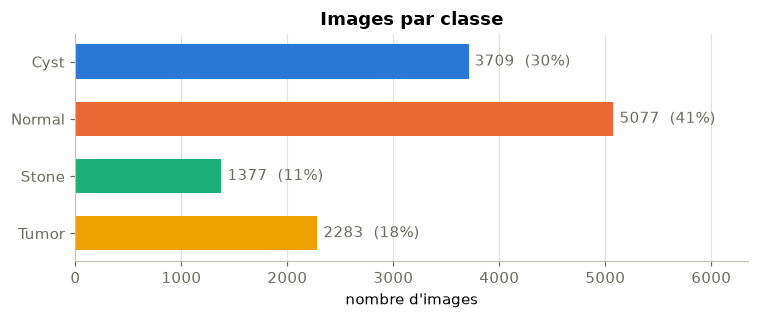

Ratio max/min : 3.7  (Normal vs Stone)


In [5]:
counts = df["cls"].value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(CLASSES, counts.values, color=[CLASS_COLORS[c] for c in CLASSES], height=0.6)
ax.bar_label(bars, [f"{n}  ({n / counts.sum():.0%})" for n in counts.values], padding=4, color=INK_MUTED)
ax.invert_yaxis(); ax.set_xlabel("nombre d'images"); ax.set_title("Images par classe")
ax.set_xlim(0, counts.max() * 1.25); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(f"Ratio max/min : {counts.max() / counts.min():.1f}  (Normal vs Stone)")

**Observation :** le dataset est déséquilibré, Stone est 3,7× moins représentée que Normal.
Il faudra un split **stratifié**, une loss **pondérée** (ou un sur-échantillonnage) et des métriques par classe
(F1 macro, rappel par classe) plutôt que l'accuracy seule.

## 3. Format des images

In [6]:
print("Modes PIL :", df["mode"].value_counts().to_dict())
print("Images dont les 3 canaux R, G, B sont identiques :", f"{df['channels_equal'].mean():.1%}")

Modes PIL : {'RGB': 12446}
Images dont les 3 canaux R, G, B sont identiques : 100.0%


**Observation :** toutes les images sont stockées en RGB, mais les trois canaux sont identiques : ce sont des
images **en niveaux de gris**. On peut travailler sur **1 canal** (3× moins de mémoire, aucune perte d'information).

## 4. Dimensions et types de coupe

In [7]:
sizes = df.groupby(["width", "height"]).size().sort_values(ascending=False)
print(f"{len(sizes)} tailles différentes. Les plus fréquentes :")
sizes.head(8).to_frame("n")

77 tailles différentes. Les plus fréquentes :


,,n
width,height,
512,512,7709
798,646,240
804,651,179
768,622,177
840,680,171
764,619,160
1236,1001,155
787,636,141


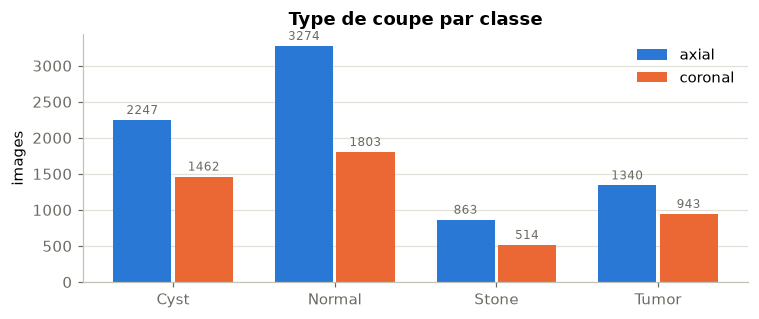

view,% axial,% coronal
cls,,
Cyst,60.6,39.4
Normal,64.5,35.5
Stone,62.7,37.3
Tumor,58.7,41.3


In [8]:
view_ct = pd.crosstab(df["cls"], df["view"]).reindex(CLASSES)
fig, ax = plt.subplots(figsize=(7, 3))
x = np.arange(len(CLASSES)); w = 0.38
for i, v in enumerate(["axial", "coronal"]):
    b = ax.bar(x + (i - 0.5) * w, view_ct[v], w - 0.02, color=VIEW_COLORS[v], label=v)
    ax.bar_label(b, padding=2, fontsize=8, color=INK_MUTED)
ax.set_xticks(x, CLASSES); ax.set_ylabel("images"); ax.legend(); ax.grid(axis="x", visible=False)
ax.set_title("Type de coupe par classe")
plt.tight_layout(); plt.show()
(view_ct.div(view_ct.sum(axis=1), axis=0) * 100).round(1).rename(columns=lambda c: f"% {c}")

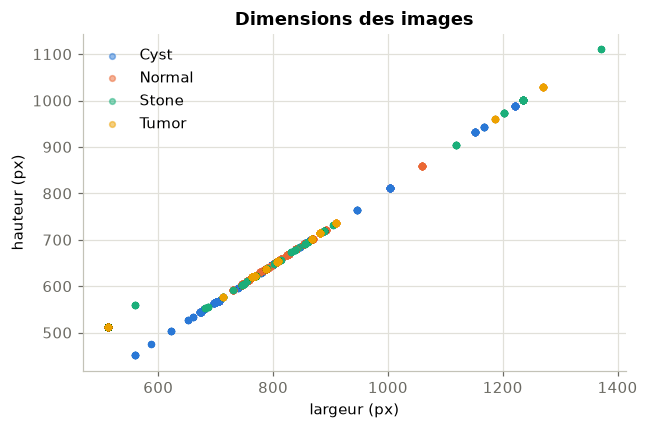

Ratio largeur/hauteur des coupes coronales : 1.236 ± 0.001


In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
for cls in CLASSES:
    g = df[df["cls"] == cls]
    ax.scatter(g["width"], g["height"], s=14, alpha=0.5, color=CLASS_COLORS[cls], label=cls)
ax.set_xlabel("largeur (px)"); ax.set_ylabel("hauteur (px)"); ax.legend()
ax.set_title("Dimensions des images")
plt.tight_layout(); plt.show()
ratio = (df.loc[df.view == "coronal", "width"] / df.loc[df.view == "coronal", "height"])
print(f"Ratio largeur/hauteur des coupes coronales : {ratio.mean():.3f} ± {ratio.std():.3f}")

**Observations :**
- Deux familles d'images : les **512×512** sont des coupes **axiales**, les images rectangulaires (une trentaine
  de tailles, ratio ≈ 1,24) sont des coupes **coronales** (voir exemples ci-dessous).
- Les tailles des coupes coronales sont **spécifiques à chaque classe** (ex. 1236×1001 n'existe que dans Stone).
  Un modèle pourrait apprendre la classe à partir de la géométrie de l'image plutôt que du rein. Il faut donc
  **uniformiser la géométrie** : redimensionner en carré déformerait les coronales. On fera plutôt un **padding noir
  jusqu'au carré**, puis un resize.

## 5. Exemples visuels

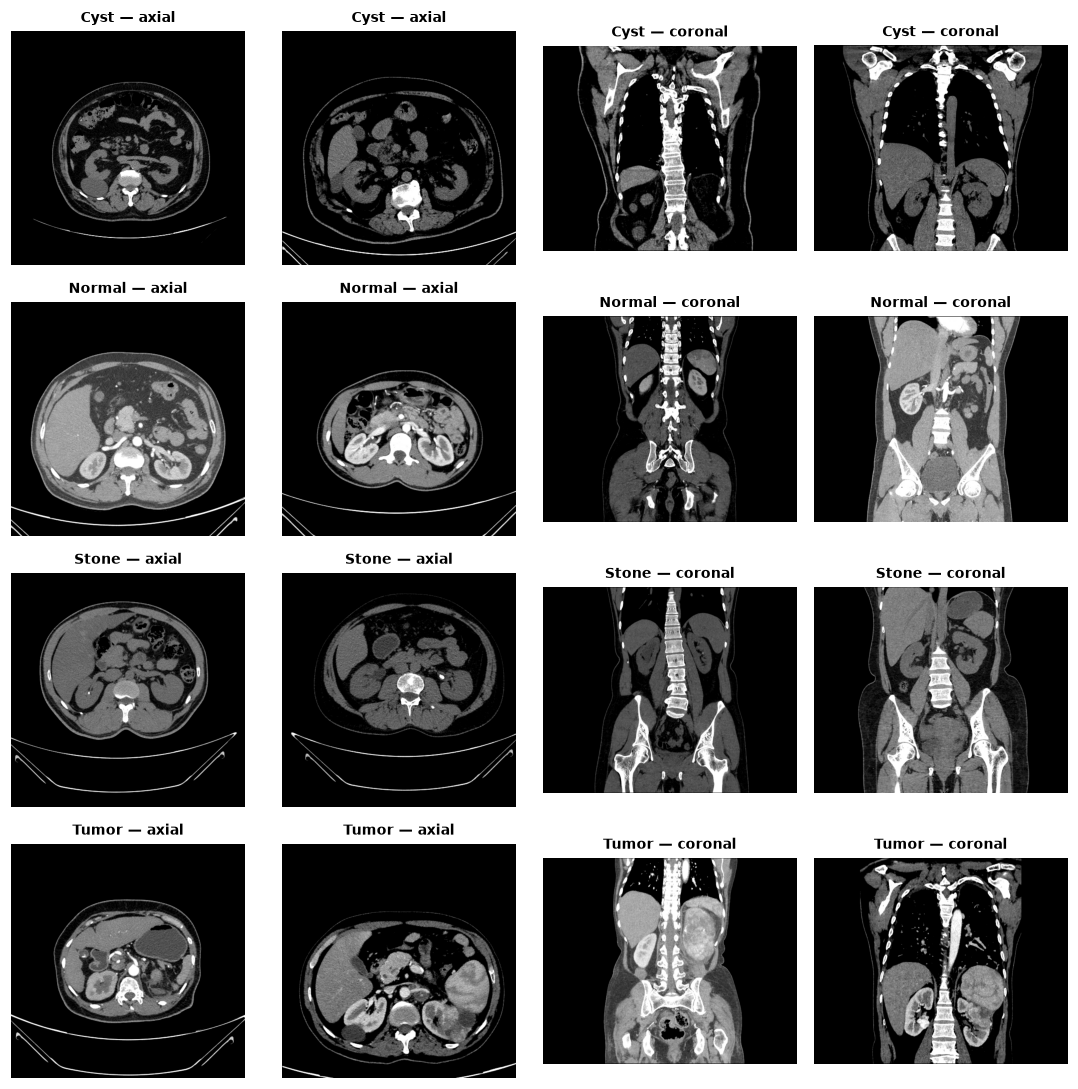

In [10]:
rng = np.random.RandomState(0)
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for r, cls in enumerate(CLASSES):
    picks = []
    for v in ["axial", "coronal"]:
        g = df[(df.cls == cls) & (df.view == v)]
        picks += list(g.sample(2, random_state=rng)["path"])
    for c, p in enumerate(picks):
        ax = axes[r, c]
        ax.imshow(Image.open(p).convert("L"), cmap="gray"); ax.axis("off")
        ax.set_title(f"{cls} — {'axial' if c < 2 else 'coronal'}", fontsize=9)
plt.tight_layout(); plt.show()

**Observation :** coupes de scanner abdominal, rein visible de part et d'autre de la colonne vertébrale. Les coupes
axiales montrent parfois la table du scanner sous le patient. Le fond est noir. Les lésions (kyste, calcul,
tumeur) occupent une petite partie de l'image : une résolution trop faible pourrait les faire disparaître
(un calcul fait parfois quelques pixels).

## 6. Intensités des pixels

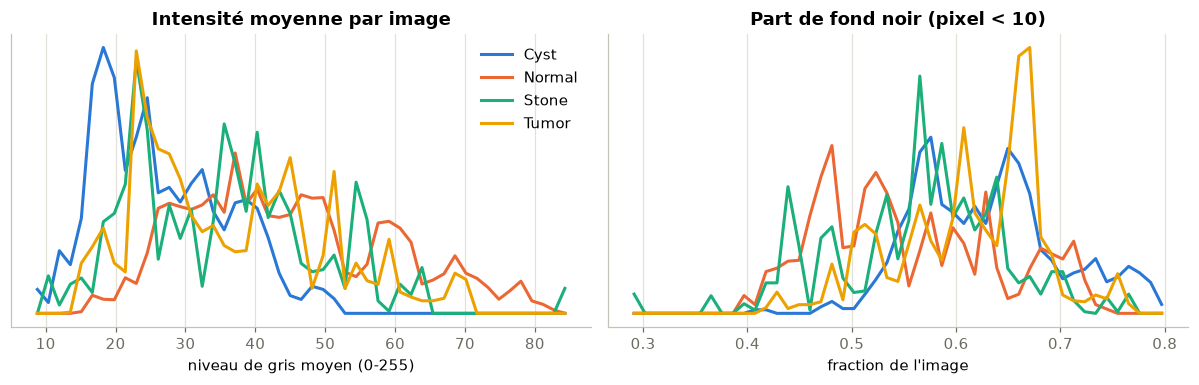

mean_intensity         black_fraction       
                 mean     std           mean    std
cls                                                
Cyst           26.592   9.280          0.630  0.070
Normal         44.766  14.620          0.554  0.085
Stone          35.491  13.362          0.562  0.082
Tumor          36.383  13.449          0.612  0.070

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for metric, ax, title in [("mean_intensity", axes[0], "Intensité moyenne par image"),
                          ("black_fraction", axes[1], "Part de fond noir (pixel < 10)")]:
    bins = np.linspace(df[metric].min(), df[metric].max(), 50)
    for cls in CLASSES:
        h, e = np.histogram(df.loc[df.cls == cls, metric], bins=bins, density=True)
        ax.plot((e[1:] + e[:-1]) / 2, h, color=CLASS_COLORS[cls], label=cls)
    ax.set_title(title); ax.set_yticks([])
axes[0].set_xlabel("niveau de gris moyen (0-255)"); axes[1].set_xlabel("fraction de l'image")
axes[0].legend()
plt.tight_layout(); plt.show()
df.groupby("cls")[["mean_intensity", "black_fraction"]].describe().loc[:, (slice(None), ["mean", "std"])].round(3)

**Observation :** les distributions d'intensité diffèrent entre classes (Normal plus clair en moyenne),
en partie à cause de la proportion de coupes coronales et du cadrage. La normalisation (`[0,1]` puis centrage)
suffit, mais il faudra vérifier que le modèle ne s'appuie pas uniquement sur ces différences globales.

## 7. Doublons exacts

In [12]:
dup_groups = df.groupby("md5").filter(lambda g: len(g) > 1).groupby("md5")
n_extra = sum(len(g) - 1 for _, g in dup_groups)
cross = sum(g["cls"].nunique() > 1 for _, g in dup_groups)
print(f"{dup_groups.ngroups} groupes de fichiers identiques (octet par octet)")
print(f"{n_extra} fichiers en trop  ({n_extra / len(df):.1%} du dataset)")
print(f"groupes partagés entre 2 classes : {cross}")
dups = df[df.duplicated("md5", keep="first")]
dups["cls"].value_counts().reindex(CLASSES, fill_value=0).to_frame("doublons à retirer")

517 groupes de fichiers identiques (octet par octet)
517 fichiers en trop  (4.2% du dataset)
groupes partagés entre 2 classes : 0


,doublons à retirer
cls,
Cyst,425
Normal,75
Stone,17
Tumor,0


In [13]:
# Exemple : où se trouvent les copies ?
ex = df[df.md5.isin(dups.md5)].groupby("md5")["file"].apply(list).head(5)
for files in ex: print(files)

['Cyst- (343).jpg', 'Cyst- (423).jpg']
['Cyst- (1142).jpg', 'Cyst- (1292).jpg']
['Cyst- (1080).jpg', 'Cyst- (1230).jpg']
['Cyst- (1180).jpg', 'Cyst- (1330).jpg']
['Cyst- (2318).jpg', 'Cyst- (2356).jpg']


**Observation :** 517 images (4 %, surtout dans Cyst) sont des copies exactes d'une autre image de la même classe. Si une copie va
en train et l'autre en test, le test est faussé. On les **supprime** avant le split.

## 8. Coupes consécutives quasi identiques

Les fichiers sont numérotés dans l'ordre : on soupçonne que des numéros voisins sont des **coupes successives
du même examen**. On mesure la distance entre deux images = moyenne de |différence| sur des miniatures 32×32
(niveaux de gris dans [0,1]).

In [14]:
def thumb(p, size=32):
    with Image.open(p) as im:
        im.draft("L", (size * 4, size * 4))
        return np.asarray(im.convert("L").resize((size, size)), dtype=np.float32).ravel() / 255

T = np.stack([thumb(p) for p in df["path"]])
same_cls_next = (df["cls"] == df["cls"].shift(-1)).to_numpy()[:-1]
d_consec = np.abs(T[1:] - T[:-1]).mean(1)[same_cls_next]
i, j = np.random.RandomState(0).randint(0, len(T), (2, 20000))
d_random = np.abs(T[i] - T[j]).mean(1)
print(f"distance médiane  — coupes consécutives : {np.median(d_consec):.4f}   paires aléatoires : {np.median(d_random):.4f}")
print(f"{(d_consec < 0.01).mean():.1%} des paires consécutives sont à moins de 0.01")

distance médiane  — coupes consécutives : 0.0034   paires aléatoires : 0.1402
97.8% des paires consécutives sont à moins de 0.01


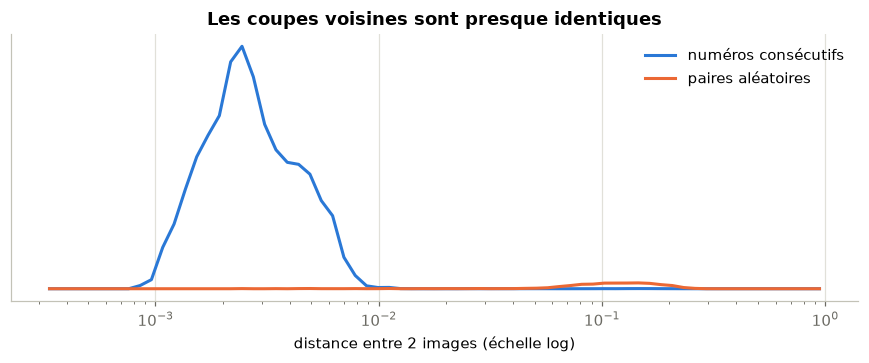

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.logspace(-3.5, 0, 70)
for d, name, color in [(d_consec, "numéros consécutifs", "#2a78d6"), (d_random, "paires aléatoires", "#eb6834")]:
    h, e = np.histogram(d, bins=bins, density=True)
    ax.plot(np.sqrt(e[1:] * e[:-1]), h * np.diff(np.log10(e)), color=color, label=name)
ax.set_xscale("log"); ax.set_yticks([]); ax.set_xlabel("distance entre 2 images (échelle log)")
ax.set_title("Les coupes voisines sont presque identiques"); ax.legend()
plt.tight_layout(); plt.show()

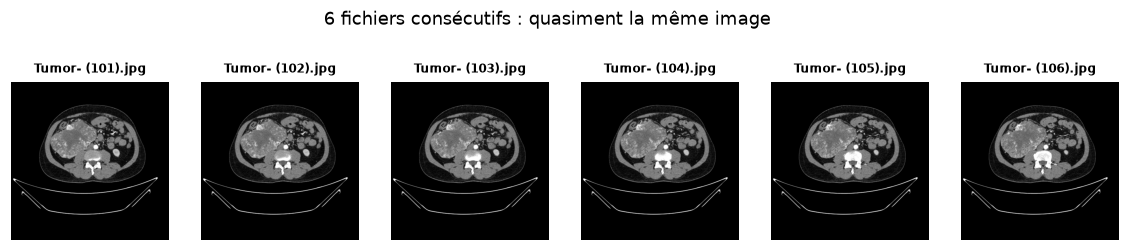

In [16]:
start = df.index[(df.cls == "Tumor")][100]
fig, axes = plt.subplots(1, 6, figsize=(13, 2.6))
for k, ax in enumerate(axes):
    row = df.loc[start + k]
    ax.imshow(Image.open(row.path).convert("L"), cmap="gray"); ax.axis("off"); ax.set_title(row.file, fontsize=8)
plt.suptitle("6 fichiers consécutifs : quasiment la même image", y=1.02); plt.show()

**Observation (la plus importante du notebook) :** ~98 % des paires de fichiers consécutifs sont quasi identiques (distance < 0,01, contre ~0,14 pour deux images au hasard).
Le dataset est composé de **séries de coupes** d'un même examen (patient), mais **aucun identifiant patient**
n'est fourni.

Avec un split aléatoire image par image, une coupe en test a presque toujours sa voisine en train : le modèle
est évalué sur des images qu'il a quasiment déjà vues, et l'accuracy (~99,9 % avec le premier baseline) est
**fortement surestimée**. Il faut reconstituer ces séries et faire un **split par série**.

## 9. Conclusions → décisions pour le prétraitement

| Constat | Décision (notebook 02) |
|---|---|
| Classes déséquilibrées (Stone 11 %, Normal 41 %) | split stratifié, loss pondérée, F1 macro + rappel par classe |
| RGB mais 3 canaux identiques | conversion en 1 canal (niveaux de gris) |
| 2 types de coupe, tailles variables et spécifiques aux classes | padding noir jusqu'au carré puis resize (pas de déformation) |
| 517 doublons exacts (4 %) | suppression avant le split |
| Coupes consécutives quasi identiques, pas d'ID patient | regroupement en **séries**, split **par série** |
| Lésions petites | garder une résolution suffisante (128 px pour le baseline, à augmenter ensuite) |